# Case Study 04 — Designing and Reading a Checkout A/B Test

**Experiment design · power and sample size · minimum detectable effect · test duration · the peeking problem ·
sample-ratio mismatch · guardrail metrics · novelty effects · reading a result as a decision**

| | |
|---|---|
| **Domain** | Product: payments app checkout |
| **Stakeholder** | Product Manager (Payments) and Head of Product |
| **Difficulty** | Intermediate |
| **Importance** | 🔴 MUST GO THROUGH |
| **Builds on** | Case 01 (CIs, Type I/II errors, power), Case 03 (two-proportion tests, randomisation checks) |
| **Data** | 28 days of pre-test traffic; 14-day user-level experiment (~66,000 users) |

> **This dataset is synthetic** and was generated to reproduce a realistic business scenario. It is not actual
> customer data. See `src/generate_data.py`.

**What you will learn**

1. How to **design** an A/B test *before* it starts: metric, unit of randomisation, baseline, minimum detectable
   effect (MDE), α, power, sample size and duration.
2. Why **checking results every day and stopping when p < 0.05** inflates false positives, and why it also inflates
   the effect estimates of real winners.
3. How to detect a **broken experiment** with a sample-ratio-mismatch (SRM) check, and how to diagnose it.
4. How to read a result against **two** thresholds: zero (is it real?) and the MDE (is it big enough?).
5. Why **guardrail metrics** and **segment checks** matter before a rollout.

This case has three parts: **A. Design** (before launch), **B. The peeking problem** (during the test),
**C. Reading the result** (after the test).

## Section 1 — Business context

You are the data scientist embedded in the **Payments** product team of a consumer payments app. Users pay utility
bills through a 3-step checkout. The team has built a **one-tap checkout** and believes it will reduce drop-off.

The Product Manager writes:

> *"We want to A/B test one-tap checkout. Engineering says rollout carries risk (new payment SDK, possible fraud-rule
> interactions), so leadership will only ship if it improves checkout completion by **at least 1 percentage
> point**. How long do we need to run the test? We'd like an answer in a week if possible."*

Three days into the test, the PM messages again:

> *"Dashboard shows treatment +1.8 points, p = 0.03. That's significant! Can we stop and ship?"*

At the end of the test the dashboard shows a warning: **"Sample ratio mismatch detected"**.

## Section 2 — Business questions

**Before the test**
1. What exactly are we measuring, and for whom?
2. How many users, and how many days, do we need to reliably detect a 1-point improvement?

**During the test**
3. Can we stop on day 3 because p < 0.05?

**After the test**
4. Can we trust this experiment at all (the SRM warning)?
5. Did one-tap checkout improve completion? By how much, and is it at least 1 point?
6. Did it harm anything (guardrails)? Is it safe to ship to everyone?

## Section 3 — Statistical translation

| # | Business question | Statistical question | Method |
|---|---|---|---|
| 1 | What do we measure? | Primary metric, unit of analysis, guardrails | Metric design |
| 2 | How long to run? | n per arm for power 80% to detect Δ = 1 pp at α = 5% (two-sided), given baseline p₀ | **Power analysis / sample size**, MDE curves |
| 3 | Stop on day 3? | What is the false-positive rate of "test daily, stop at first p < 0.05"? | **Simulation of A/A tests** with repeated looks |
| 4 | Trust the experiment? | Is the observed split consistent with 50/50? Where does it break? | **SRM test** (binomial / χ² goodness of fit), segment drill-down |
| 5 | Did it work? Enough? | Δ = p(T) − p(C): estimate, CI; compare the CI with 0 **and** with the 1 pp MDE | Two-proportion z-test, CI |
| 6 | Safe to ship? | Guardrail metrics; segment effects; stability over time | Proportion tests, daily-lift plot |

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "00_shared_resources").is_dir())
sys.path.insert(0, str(ROOT / "00_shared_resources"))
from utils import case_paths, save_table, fmt_p, rng_for_case
from plotting import set_style, save_fig, add_note, COLORS, PRIMARY, HIGHLIGHT, INK, INK_MUTED
from statistical_tests import proportion_ci, cohens_h

CASE_DIR = ROOT / "case_studies" / "04_checkout_ab_test"
PATHS = case_paths(CASE_DIR)
set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
rng = rng_for_case(404)
pct = plt.FuncFormatter(lambda v, _: f"{v:.0%}")

MDE = 0.01            # minimum lift leadership cares about (absolute, 1 percentage point)
ALPHA = 0.05
POWER = 0.80
TEST_TRAFFIC_SHARE = 0.10   # the test ran on 10% of app traffic
NET_VALUE_PER_PAYMENT = 10  # ₹ net revenue per completed bill payment (Finance)

---
# Part A — Designing the test (before launch)

## Section 4 — Load the planning data

In [2]:
hist = pd.read_csv(PATHS["data"] / "historical_baseline.csv", parse_dates=["date"])
hist["completion_rate"] = hist["users_completing"] / hist["users_starting_checkout"]
hist["weekday"] = hist["date"].dt.day_name()
display(hist.head(8))
p0 = hist["users_completing"].sum() / hist["users_starting_checkout"].sum()
daily_users = hist["users_starting_checkout"].mean()
print(f"Baseline completion rate (28 days): {p0:.2%}")
print(f"Average users starting a checkout per day (10% traffic slice): {daily_users:,.0f}")
print(f"Day-to-day SD of the completion rate: {hist['completion_rate'].std():.2%}")

,date,users_starting_checkout,users_completing,completion_rate,weekday
0,2026-07-06,4537,3240,0.7141,Monday
1,2026-07-07,4536,3241,0.7145,Tuesday
2,2026-07-08,4638,3289,0.7091,Wednesday
3,2026-07-09,4430,3152,0.7115,Thursday
4,2026-07-10,4615,3246,0.7034,Friday
5,2026-07-11,5457,3878,0.7106,Saturday
6,2026-07-12,5532,3972,0.7180,Sunday
7,2026-07-13,4618,3314,0.7176,Monday


Baseline completion rate (28 days): 70.98%
Average users starting a checkout per day (10% traffic slice): 4,836
Day-to-day SD of the completion rate: 0.58%


## Section 5 — Metric design

Before any power calculation, pin down **what** is measured on **whom**. Most experiment disputes are really
disputes about definitions.

| Decision | Choice | Why |
|---|---|---|
| **Unit of randomisation** | **User** (not session, not payment) | A user who sees one-tap once will expect it next time. Randomising sessions would mix experiences within a user and break independence. |
| **Unit of analysis** | User (same as randomisation) | Analysing sessions when randomising users makes standard errors too small, because a user's sessions are correlated. |
| **Primary metric** | **Checkout completion**: share of users who started a bill-payment checkout during the test and completed their first one | Directly measures the drop-off problem; binary per user. |
| **Guardrail metrics** | **Payment error rate**; completion **by platform/app version** | One-tap must not increase failed payments or break any user group. |
| **Population** | All users who start a checkout; exposure is logged when the checkout screen loads | Defines who enters the analysis. |
| **Pre-registered decision rule** | Ship if the 95% CI excludes 0 **and** guardrails show no harm; evaluate vs the 1 pp MDE | Fixed *before* seeing data. |

## Section 6 — Power and sample size

### 6.1 The four quantities that trade off

| Quantity | Meaning | Our choice |
|---|---|---|
| **α (significance level)** | Accepted false-positive rate: P(declare a difference \| none exists) | 5%, two-sided |
| **Power (1 − β)** | P(detect the effect \| it truly equals the MDE) | 80% |
| **MDE** | Smallest effect we *need* to detect: a **business** choice | 1 percentage point |
| **n** | Users per arm | What we solve for |

Fix any three and the fourth is determined. **Halving the MDE roughly quadruples the sample size**, because the
standard error shrinks only with √n.

### 6.2 Sample size by hand

For two proportions, a standard approximation is

  n per arm ≈ (z₁₋α/₂ + z₁₋β)² × [p₁(1−p₁) + p₂(1−p₂)] / Δ²

where p₁ = baseline, p₂ = baseline + MDE, Δ = MDE.

In [3]:
p1, p2 = p0, p0 + MDE
z_a, z_b = stats.norm.ppf(1 - ALPHA / 2), stats.norm.ppf(POWER)
n_hand = (z_a + z_b) ** 2 * (p1 * (1 - p1) + p2 * (1 - p2)) / MDE ** 2
n_sm = NormalIndPower().solve_power(effect_size=cohens_h(p2, p1), alpha=ALPHA, power=POWER, ratio=1.0)
days_needed = 2 * n_sm / daily_users
print(f"z(1-α/2) = {z_a:.3f}, z(power) = {z_b:.3f}")
print(f"n per arm (formula)     = {n_hand:,.0f}")
print(f"n per arm (statsmodels) = {n_sm:,.0f}  (uses Cohen's h; nearly identical)")
print(f"Total users needed = {2 * n_sm:,.0f}  ->  {days_needed:.1f} days at {daily_users:,.0f} users/day")

z(1-α/2) = 1.960, z(power) = 0.842
n per arm (formula)     = 31,994
n per arm (statsmodels) = 31,996  (uses Cohen's h; nearly identical)
Total users needed = 63,992  ->  13.2 days at 4,836 users/day


About **32,000 users per arm**, i.e. **about 13.2 days** of traffic. The plan:

- **Run for 14 days, two full weeks**, even if the sample size is reached a little earlier. Behaviour differs
  by weekday (weekend traffic is ~15% higher with a different mix). A test that ends on a Wednesday over-represents
  some days. **Always run whole weeks.**
- The PM's "one week" would give only about half the needed sample. The next calculation shows what that costs.

In [4]:
# What can each duration detect? MDE at 80% power for a range of durations.
def mde_for_n(n_arm, p=p0, alpha=ALPHA, power=POWER):
    # Solve for the smallest lift detectable with n_arm users per arm.
    h = NormalIndPower().solve_power(nobs1=n_arm, alpha=alpha, power=power, ratio=1.0)
    p2 = np.sin(np.arcsin(np.sqrt(p)) + h / 2) ** 2        # invert Cohen's h
    return p2 - p

def power_for(n_arm, lift, p=p0, alpha=ALPHA):
    return NormalIndPower().power(effect_size=cohens_h(p + lift, p), nobs1=n_arm, alpha=alpha, ratio=1.0)

plan = pd.DataFrame({"days": [7, 14, 21, 28]})
plan["users_per_arm"] = plan["days"] * daily_users / 2
plan["MDE_pp (80% power)"] = plan["users_per_arm"].apply(mde_for_n) * 100
plan["power_for_1pp_lift"] = plan["users_per_arm"].apply(lambda n: power_for(n, MDE))
save_table(plan, "test_duration_plan", PATHS["tables"], index=False)
plan

,days,users_per_arm,MDE_pp (80% power),power_for_1pp_lift
0,7,"16,924.3750",1.3722,0.5310
1,14,"33,848.7500",0.9724,0.8216
2,21,"50,773.1250",0.7947,0.9417
3,28,"67,697.5000",0.6886,0.9828


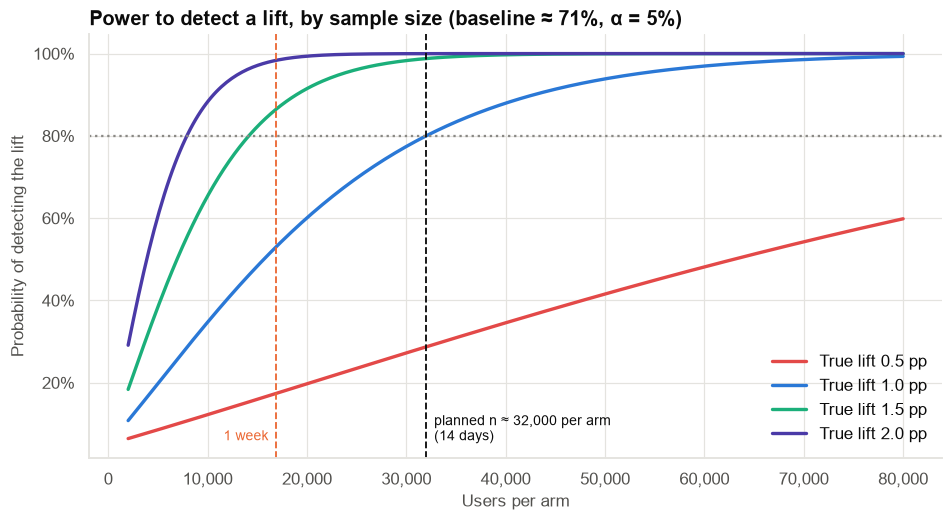

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
n_grid = np.linspace(2_000, 80_000, 300)
for lift, color in [(0.005, COLORS["red"]), (0.01, PRIMARY), (0.015, COLORS["aqua"]), (0.02, COLORS["violet"])]:
    ax.plot(n_grid, [power_for(n, lift) for n in n_grid], color=color, lw=2.2, label=f"True lift {lift * 100:.1f} pp")
ax.axhline(POWER, color=INK_MUTED, ls=":", lw=1.5)
ax.axvline(n_sm, color=INK, ls="--", lw=1.2)
ax.text(n_sm + 800, 0.06, f"planned n ≈ {round(n_sm, -3):,.0f} per arm\n(14 days)", fontsize=9)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.axvline(7 * daily_users / 2, color=HIGHLIGHT, ls="--", lw=1.2)
ax.text(7 * daily_users / 2 - 800, 0.06, "1 week", ha="right", fontsize=9, color=HIGHLIGHT)
ax.yaxis.set_major_formatter(pct)
ax.set(title="Power to detect a lift, by sample size (baseline ≈ 71%, α = 5%)",
       xlabel="Users per arm", ylabel="Probability of detecting the lift")
ax.legend(loc="lower right")
save_fig(fig, "fig01_power_curves", PATHS["figures"])
plt.show()

**Observation.** At ~33,000 users per arm, a true 1 pp lift is detected 80% of the time. After one week (≈ 17,000
per arm) the power to detect 1 pp is only about half. The test would miss a real 1 pp improvement as often as it
caught it.

**Interpretation.** Power curves make the trade-off visible: small effects need large samples. A lift of 0.5 pp
would need about four times as many users.

**Business implication.** Ending at one week risks a **false negative** (killing a good feature), and any
"significant" result would come with a very wide CI.

**Caveat.** Power is computed for an *assumed* true effect. If the true lift is smaller than 1 pp, power is lower
than shown, and that is acceptable by design, because leadership said smaller lifts are not worth shipping.

---
# Part B — The peeking problem (during the test)

## Section 7 — Why "stop when p < 0.05" is broken

A p-value is calibrated for **one** look at a **pre-specified** sample size. If you look every day and stop the
first time p < 0.05, you are giving chance 14 opportunities to produce a "significant" result. Let us measure the
damage with **A/A tests**: simulated experiments where both arms are identical, so every "significant" result is a
false positive.

In [6]:
def simulate_aa(n_sims=4_000, days=14, users_per_arm_day=int(daily_users / 2), p=p0):
    # Daily conversions in two identical arms; cumulative z-statistic after each day.
    c = rng.binomial(users_per_arm_day, p, size=(n_sims, days)).cumsum(axis=1)
    t = rng.binomial(users_per_arm_day, p, size=(n_sims, days)).cumsum(axis=1)
    n = users_per_arm_day * np.arange(1, days + 1)
    pc, pt = c / n, t / n
    pool = (c + t) / (2 * n)
    z = (pt - pc) / np.sqrt(pool * (1 - pool) * 2 / n)
    return 2 * stats.norm.sf(np.abs(z))        # p-value after each day, shape (n_sims, days)

pvals = simulate_aa()
fixed_fpr = (pvals[:, -1] < ALPHA).mean()
peek_fpr = (pvals < ALPHA).any(axis=1).mean()
by_looks = pd.Series({k: (pvals[:, :k] < ALPHA).any(axis=1).mean() for k in range(1, 15)}, name="false positive rate")

# A stricter constant threshold for 14 daily looks (Pocock-style), calibrated by simulation to keep 5% overall.
grid = np.linspace(0.001, 0.05, 400)
overall = np.array([(pvals < a).any(axis=1).mean() for a in grid])
pocock = grid[np.argmin(np.abs(overall - ALPHA))]
pvals_check = simulate_aa()                      # fresh simulations to verify the calibrated threshold
pocock_fpr = (pvals_check < pocock).any(axis=1).mean()

print(f"False-positive rate, single look at day 14          : {fixed_fpr:.1%}")
print(f"False-positive rate, peek daily & stop at p < 0.05   : {peek_fpr:.1%}")
print(f"Per-look threshold that keeps 5% overall with 14 looks: p < {pocock:.4f}  (verified on fresh sims: {pocock_fpr:.1%})")

False-positive rate, single look at day 14          : 5.4%
False-positive rate, peek daily & stop at p < 0.05   : 22.4%
Per-look threshold that keeps 5% overall with 14 looks: p < 0.0082  (verified on fresh sims: 4.4%)


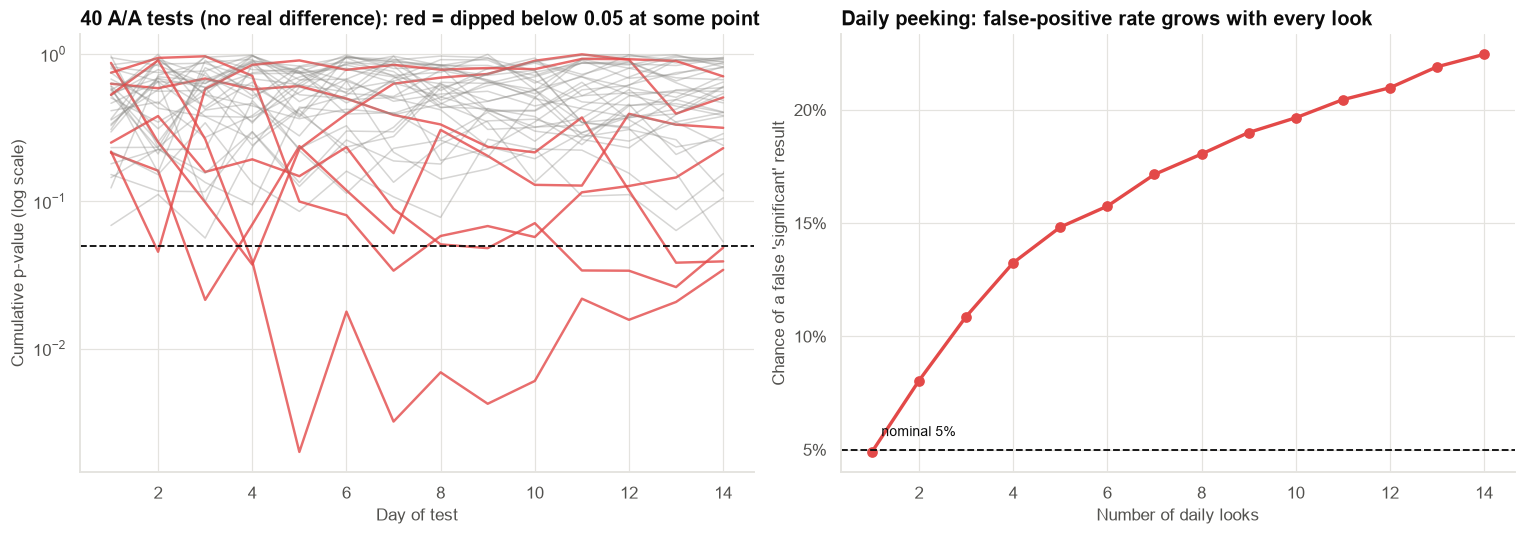

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
for i in range(40):
    path = pvals[i]
    crossed = (path < ALPHA).any()
    ax.plot(range(1, 15), path, color=COLORS["red"] if crossed else INK_MUTED, alpha=0.8 if crossed else 0.35,
            lw=1.6 if crossed else 1)
ax.axhline(ALPHA, color=INK, ls="--", lw=1.2)
ax.set_yscale("log")
ax.set(title="40 A/A tests (no real difference): red = dipped below 0.05 at some point",
       xlabel="Day of test", ylabel="Cumulative p-value (log scale)")
ax = axes[1]
ax.plot(by_looks.index, by_looks.values, marker="o", color=COLORS["red"], lw=2.2)
ax.axhline(ALPHA, color=INK, ls="--", lw=1.2)
ax.text(1.2, ALPHA + 0.006, "nominal 5%", fontsize=9)
ax.yaxis.set_major_locator(plt.MultipleLocator(0.05))
ax.yaxis.set_major_formatter(pct)
ax.set(title="Daily peeking: false-positive rate grows with every look", xlabel="Number of daily looks",
       ylabel="Chance of a false 'significant' result")
fig.tight_layout()
save_fig(fig, "fig02_peeking_simulation", PATHS["figures"])
plt.show()

**Observation.** With a single look at the planned end, the false-positive rate is about 5%, as promised. Peeking
every day and stopping at the first p < 0.05 roughly **quadruples** it, to around 20%. P-value paths wander,
and over 14 looks many of them dip below 0.05 at some point purely by chance.

**Interpretation.** A p-value is a statement about a **pre-planned** analysis. Each extra look is another lottery
ticket for chance.

**Business implication.** A team that peeks and stops early will ship far more "winners" that do nothing, and will
then wonder why launched features never move the business metrics.

**What to do instead.**
1. **Fixed horizon:** decide n in advance (Part A), look once at the end. Looking during the test only for
   *safety/bugs* (not significance) is fine.
2. **Sequential designs**, if early stopping is genuinely needed: use stricter per-look thresholds. A constant
   threshold (Pocock-style) of about p < 0.008 per look keeps the overall rate at 5% for 14 looks. Spending functions
   such as O'Brien-Fleming are stricter early and looser late. Always-valid methods (mSPRT) also exist.

### 7.1 Back to the PM's day-3 request

The PM's p = 0.03 on day 3 would not pass a 14-look sequential threshold (≈ 0.008). Even if the effect is real,
stopping early has a second cost, which Part C shows: **early winners are overestimated**.

---
# Part C — Reading the result (after the test)

## Section 8 — Load the experiment data

In [8]:
exp = pd.read_csv(PATHS["data"] / "experiment_users.csv")
print(f"{len(exp):,} users, {exp['day'].nunique()} days")
display(exp.head())
print(exp.dtypes.to_string())

66,329 users, 14 days


,user_id,day,variant,platform,app_version,completed,payment_error,payment_amount
0,U7000000,1,treatment,iOS,v5+,1,0,"1,168.0000"
1,U7000001,1,treatment,iOS,v5+,1,0,"1,290.0000"
2,U7000002,1,treatment,Android,v5+,1,0,"1,339.0000"
3,U7000003,1,treatment,Android,v5+,1,0,"1,608.0000"
4,U7000004,1,control,iOS,v5+,1,0,"1,481.0000"


user_id               str
day                 int64
variant               str
platform              str
app_version           str
completed           int64
payment_error       int64
payment_amount    float64


| Column | Meaning |
|---|---|
| `user_id` | One row per user (first checkout during the test) |
| `day` | Test day the user was first exposed (1–14) |
| `variant` | `control` (old 3-step) or `treatment` (one-tap), randomised 50/50 at user level |
| `platform`, `app_version` | iOS / Android; `v5+` or `pre-v5` (older Android app) |
| `completed` | **Primary metric**: completed the payment (1/0) |
| `payment_error` | **Guardrail**: payment failed with an error (1/0) |
| `payment_amount` | ₹, only for completed payments |

## Section 9 — Data quality and experiment integrity: the SRM check

**Always check the experiment before the result.** If the randomisation or logging is broken, the result is
meaningless however small the p-value.

In [9]:
print(f"Duplicate user_ids: {exp['user_id'].duplicated().sum()},  missing values: {exp.drop(columns='payment_amount').isna().sum().sum()}")
counts = exp["variant"].value_counts()
srm = stats.binomtest(int(counts["treatment"]), len(exp), 0.5)
print(f"\nControl {counts['control']:,} vs treatment {counts['treatment']:,}  "
      f"({counts['treatment'] / len(exp):.2%} treatment, planned 50%)")
print(f"SRM test (exact binomial): p = {srm.pvalue:.1e}")

Duplicate user_ids: 0,  missing values: 0

Control 33,895 vs treatment 32,434  (48.90% treatment, planned 50%)
SRM test (exact binomial): p = 1.4e-08


**SRM detected.** With ~66,000 users, a 50/50 coin would almost never produce a split this lopsided (p ≈ 10⁻⁸).
About 1,500 treatment users are "missing". Randomisation does not lose users by itself. **Something removed users
from one arm.**

**Why this invalidates the naive comparison:** if the missing users are not a random subset (e.g., users who hit a
bug and left), the two arms are no longer comparable and the difference in completion is biased, in an
unknown direction. Industry practice: **do not interpret a test with an SRM until you understand it.**

### 9.1 Diagnose: where is the imbalance?

In [10]:
def srm_table(df, by):
    t = df.groupby(by + ["variant"]).size().unstack("variant")
    t["treatment_share"] = t["treatment"] / (t["control"] + t["treatment"])
    t["srm_p"] = [stats.binomtest(int(r["treatment"]), int(r["control"] + r["treatment"]), 0.5).pvalue for _, r in t.iterrows()]
    return t

srm_by = pd.concat([srm_table(exp, ["platform"]).assign(level="platform"),
                    srm_table(exp, ["app_version"]).assign(level="app_version"),
                    srm_table(exp, ["platform", "app_version"]).assign(level="platform × version")])
save_table(srm_by, "srm_diagnosis", PATHS["tables"])
srm_by

variant,control,treatment,treatment_share,srm_p,level
Android,22143,20672,0.4828,0.0000,platform
iOS,11752,11762,0.5002,0.9532,platform
pre-v5,3459,2187,0.3874,0.0000,app_version
v5+,30436,30247,0.4984,0.4454,app_version
"(Android, pre-v5)",3459,2187,0.3874,0.0000,platform × version
"(Android, v5+)",18684,18485,0.4973,0.3044,platform × version
"(iOS, v5+)",11752,11762,0.5002,0.9532,platform × version


In [11]:
pre = exp[exp["app_version"] == "pre-v5"]
v5 = exp[exp["app_version"] == "v5+"]
n_pre_c, n_pre_t = (pre["variant"] == "control").sum(), (pre["variant"] == "treatment").sum()
missing = n_pre_c - n_pre_t
print(f"Pre-v5 users: control {n_pre_c:,}, treatment {n_pre_t:,}  ->  about {missing:,} treatment users missing "
      f"({missing / n_pre_c:.0%} of the expected {n_pre_c:,})")
print("Pre-v5 users who ARE logged:")
display(pre.groupby("variant")[["completed", "payment_error"]].mean().style.format("{:.1%}"))

Pre-v5 users: control 3,459, treatment 2,187  ->  about 1,272 treatment users missing (37% of the expected 3,459)


Pre-v5 users who ARE logged:


,completed,payment_error
variant,,
control,60.5%,1.9%
treatment,56.6%,5.9%


**Root cause found.** The imbalance is entirely in the **pre-v5 Android app** (about 9% of users). In v5+ and on iOS
the split is a clean 50/50. Engineering confirms: on pre-v5 the one-tap screen **crashes before the exposure
event is logged** for roughly a third of treatment users. Those users never appear in the data. They did not
complete their payment.

The pre-v5 treatment users who *are* logged also show **three times the payment-error rate** (≈ 6% vs ≈ 2%).

**Two consequences:**
1. **Pre-v5 users must not get one-tap** until the crash is fixed. If the ~37% missing users are counted as
   failures (they crashed out), pre-v5 completion on one-tap is roughly **36% vs 60.5%** on the old flow. That is a
   serious regression for ~9% of users, which the overall average would have hidden.
2. **For the decision about v5+ users**, we can analyse the v5+ segment cleanly: app version is a
   **pre-treatment** attribute (it was fixed before randomisation), the bug does not touch v5+, and the v5+ split
   passes the SRM check. Restricting both arms to v5+ keeps the comparison randomised.

> **Rule:** you may restrict an experiment analysis to a subgroup defined by **pre-treatment** characteristics, applied
> identically to both arms. You may **not** drop users based on anything that happened *after* assignment (e.g.,
> "users who saw the new screen"), because treatment itself can change who ends up in that group.

v5+ split: 49.84% treatment, SRM p = 0.45  ->  clean


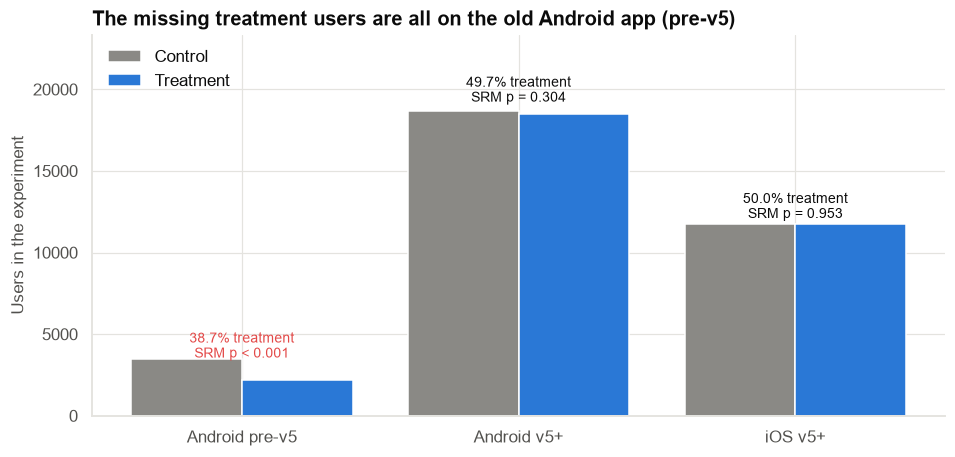

In [12]:
srm_v5 = stats.binomtest(int((v5["variant"] == "treatment").sum()), len(v5), 0.5)
print(f"v5+ split: {(v5['variant'] == 'treatment').mean():.2%} treatment, SRM p = {srm_v5.pvalue:.2f}  ->  clean")

fig, ax = plt.subplots(figsize=(10, 4.5))
seg = srm_table(exp, ["platform", "app_version"]).reset_index()
seg["label"] = seg["platform"] + " " + seg["app_version"]
x = np.arange(len(seg))
ax.bar(x - 0.2, seg["control"], width=0.4, color=INK_MUTED, label="Control")
ax.bar(x + 0.2, seg["treatment"], width=0.4, color=PRIMARY, label="Treatment")
for xi, (_, r) in zip(x, seg.iterrows()):
    ax.text(xi, max(r["control"], r["treatment"]) * 1.03, f"{r['treatment_share']:.1%} treatment\nSRM p {'< 0.001' if r['srm_p'] < 0.001 else '= ' + fmt_p(r['srm_p'])}",
            ha="center", fontsize=9, color=COLORS["red"] if r["srm_p"] < 0.01 else INK)
ax.set_xticks(x, seg["label"])
ax.set_ylim(0, seg[["control", "treatment"]].to_numpy().max() * 1.25)
ax.set(title="The missing treatment users are all on the old Android app (pre-v5)",
       ylabel="Users in the experiment")
ax.legend(loc="upper left")
save_fig(fig, "fig03_srm_diagnosis", PATHS["figures"])
plt.show()

## Section 10 — Descriptive statistics (v5+ users, the clean comparison)

In [13]:
def rates(df, metric):
    g = df.groupby("variant")[metric].agg(users="size", events="sum")
    g["rate"] = g["events"] / g["users"]
    ci = [proportion_ci(k, n) for k, n in zip(g["events"], g["users"])]
    g["ci_low"], g["ci_high"] = [c["lower"] for c in ci], [c["upper"] for c in ci]
    return g

primary = rates(v5, "completed")
guard = rates(v5, "payment_error")
save_table(primary, "primary_metric_v5", PATHS["tables"])
save_table(guard, "guardrail_v5", PATHS["tables"])
display(primary)
guard

,users,events,rate,ci_low,ci_high
variant,,,,,
control,30436,21404,0.7032,0.6981,0.7084
treatment,30247,21586,0.7137,0.7085,0.7187


,users,events,rate,ci_low,ci_high
variant,,,,,
control,30436,640,0.0210,0.0195,0.0227
treatment,30247,606,0.0200,0.0185,0.0217


## Section 11 — Method selection and assumptions

Binary outcome per user, two randomised independent arms, large counts (≈ 30,000 users and ≈ 21,500 completions per
arm): the **two-proportion z-test with a CI for the difference** (as in Case 03). The pre-registered decision rule
compares the CI with **0** (is there an effect?) and with the **1 pp MDE** (is it big enough?).

| Assumption | Check |
|---|---|
| Randomisation intact | v5+ SRM p ≈ 0.45 ✅ (the problem is isolated in pre-v5, analysed separately) |
| Independence | One row per user; user-level randomisation and analysis ✅ |
| Large counts | Thousands of events per arm ✅ |
| Fixed horizon | Analysed once at the planned day-14 end ✅ (interim looks were for monitoring only) |
| Stable effect over time | Checked below (novelty effects) ⚠️ |

## Section 12 — Analysis

### 12.1 Primary metric: v5+ users

In [14]:
x_t, n_t = int(primary.loc["treatment", "events"]), int(primary.loc["treatment", "users"])
x_c, n_c = int(primary.loc["control", "events"]), int(primary.loc["control", "users"])
lift = x_t / n_t - x_c / n_c
z, p_val = proportions_ztest([x_t, x_c], [n_t, n_c])
ci = confint_proportions_2indep(x_t, n_t, x_c, n_c, method="newcomb", compare="diff")
rel = confint_proportions_2indep(x_t, n_t, x_c, n_c, method="log", compare="ratio")
print(f"Completion: treatment {x_t / n_t:.2%} vs control {x_c / n_c:.2%}")
print(f"Lift = {lift * 100:+.2f} pp, 95% CI [{ci[0] * 100:+.2f}, {ci[1] * 100:+.2f}] pp;  z = {z:.2f}, p = {p_val:.4f}")
print(f"Relative lift = {x_t / n_t / (x_c / n_c) - 1:+.2%} (95% CI {rel[0] - 1:+.2%} to {rel[1] - 1:+.2%})")
print(f"MDE check: CI lower bound {ci[0] * 100:.2f} pp vs MDE {MDE * 100:.1f} pp")

naive = rates(exp, "completed")
naive_lift = naive.loc["treatment", "rate"] - naive.loc["control", "rate"]
print(f"\nFor reference, the naive all-user lift (INVALID because of the SRM) = {naive_lift * 100:+.2f} pp")

Completion: treatment 71.37% vs control 70.32%
Lift = +1.04 pp, 95% CI [+0.32, +1.76] pp;  z = 2.82, p = 0.0048
Relative lift = +1.48% (95% CI +0.45% to +2.52%)
MDE check: CI lower bound 0.32 pp vs MDE 1.0 pp

For reference, the naive all-user lift (INVALID because of the SRM) = +1.04 pp


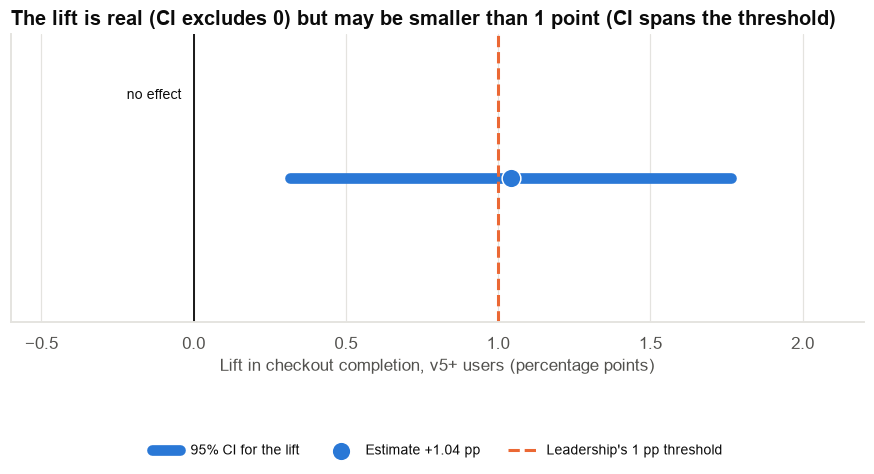

In [15]:
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot([ci[0] * 100, ci[1] * 100], [0, 0], color=PRIMARY, lw=7, solid_capstyle="round", label="95% CI for the lift")
ax.scatter(lift * 100, 0, s=150, color=PRIMARY, edgecolor="white", zorder=3, label=f"Estimate {lift * 100:+.2f} pp")
ax.axvline(0, color=INK, lw=1.2)
ax.axvline(MDE * 100, color=HIGHLIGHT, ls="--", lw=2, label="Leadership's 1 pp threshold")
ax.text(-0.04, 0.22, "no effect", ha="right", fontsize=9)
ax.set_ylim(-0.4, 0.4)
ax.set_yticks([])
ax.set_xlim(-0.6, 2.2)
ax.set(title="The lift is real (CI excludes 0) but may be smaller than 1 point (CI spans the threshold)",
       xlabel="Lift in checkout completion, v5+ users (percentage points)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.38), ncol=3, fontsize=9)
save_fig(fig, "fig04_lift_vs_thresholds", PATHS["figures"])
plt.show()

**Reading the result against both thresholds:**

| Threshold | CI position | Conclusion |
|---|---|---|
| 0 (no effect) | CI entirely above 0 | **There is a real improvement** (p ≈ 0.005) |
| 1 pp (MDE / leadership threshold) | CI spans 1 pp | **We cannot tell whether it is at least 1 point.** The best estimate is right at the threshold. |

A warning about the naive all-user lift printed above: here it happens to equal the v5+ lift (+1.04 pp),
because the two biases of the bug (missing low-completion users, and extra errors among those logged) roughly
cancel. **That is luck, not validation.** With a slightly different bug the naive number could have been badly
wrong in either direction, and nobody would have known without the SRM check.

This combination, "significant but not proven big enough", is common and is exactly why we report a CI and not just
a p-value.

### 12.2 Guardrail: payment errors

In [16]:
ge_t, gn_t = int(guard.loc["treatment", "events"]), int(guard.loc["treatment", "users"])
ge_c, gn_c = int(guard.loc["control", "events"]), int(guard.loc["control", "users"])
g_ci = confint_proportions_2indep(ge_t, gn_t, ge_c, gn_c, method="newcomb", compare="diff")
g_z, g_p = proportions_ztest([ge_t, ge_c], [gn_t, gn_c])
print(f"Payment error rate (v5+): treatment {ge_t / gn_t:.2%} vs control {ge_c / gn_c:.2%}; "
      f"difference {100 * (ge_t / gn_t - ge_c / gn_c):+.2f} pp, 95% CI [{g_ci[0] * 100:+.2f}, {g_ci[1] * 100:+.2f}] pp, p = {g_p:.2f}")

Payment error rate (v5+): treatment 2.00% vs control 2.10%; difference -0.10 pp, 95% CI [-0.33, +0.13] pp, p = 0.39


For v5+ users there is no sign of more payment errors. The CI rules out an increase larger than about 0.13
percentage points. (For pre-v5 users the guardrail fails badly, as seen in Section 9.)

### 12.3 Was the effect stable over time? Novelty and the cost of stopping early

In [17]:
daily = []
for d in range(1, 15):
    day_df = v5[v5["day"] == d]
    cum_df = v5[v5["day"] <= d]
    for kind, df in (("daily", day_df), ("cumulative", cum_df)):
        g = df.groupby("variant")["completed"].agg(["sum", "size"])
        l = g.loc["treatment", "sum"] / g.loc["treatment", "size"] - g.loc["control", "sum"] / g.loc["control", "size"]
        lo, hi = confint_proportions_2indep(g.loc["treatment", "sum"], g.loc["treatment", "size"],
                                            g.loc["control", "sum"], g.loc["control", "size"], method="newcomb", compare="diff")
        pz = proportions_ztest(g["sum"].loc[["treatment", "control"]], g["size"].loc[["treatment", "control"]])[1]
        daily.append({"day": d, "kind": kind, "lift_pp": l * 100, "ci_low_pp": lo * 100, "ci_high_pp": hi * 100, "p_value": pz})
daily = pd.DataFrame(daily)
save_table(daily, "lift_by_day", PATHS["tables"], index=False)
daily.pivot(index="day", columns="kind", values=["lift_pp", "p_value"]).round(4)

lift_pp            p_value       
kind cumulative   daily cumulative  daily
day                                      
1        2.0821  2.0821     0.1387 0.1387
2        1.9622  1.8388     0.0487 0.1919
3        1.7794  1.4056     0.0286 0.3182
4        2.0213  2.7304     0.0040 0.0503
5        1.9683  1.7608     0.0018 0.2244
6        2.3933  4.1515     0.0000 0.0012
7        1.9055 -0.6080     0.0002 0.6388
8        1.9014  1.8778     0.0001 0.1815
9        1.8841  1.7368     0.0000 0.2185
10       1.7561  0.5191     0.0001 0.7182
11       1.5102 -1.0525     0.0003 0.4643
12       1.4244  0.4443     0.0004 0.7577
13       1.2163 -0.8701     0.0016 0.5004
14       1.0411 -0.9618     0.0048 0.4619

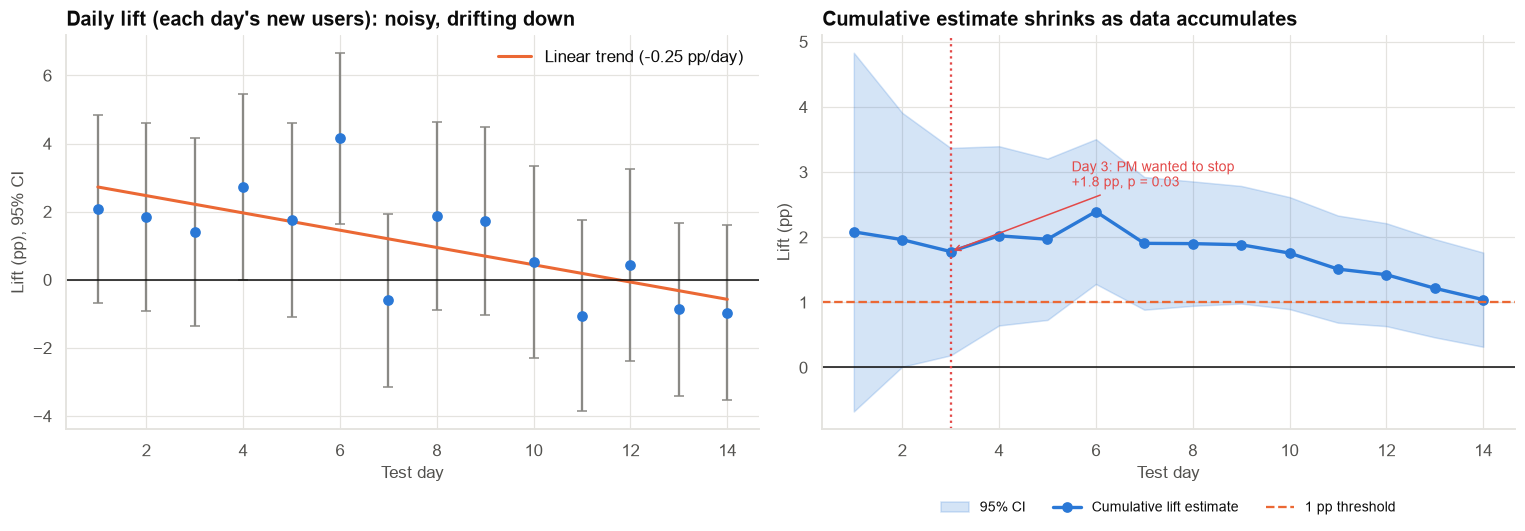

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
d_ = daily[daily["kind"] == "daily"]
ax = axes[0]
ax.errorbar(d_["day"], d_["lift_pp"], yerr=[d_["lift_pp"] - d_["ci_low_pp"], d_["ci_high_pp"] - d_["lift_pp"]],
            fmt="o", color=PRIMARY, ecolor=INK_MUTED, capsize=3)
coef = np.polyfit(d_["day"], d_["lift_pp"], 1)
ax.plot(d_["day"], np.polyval(coef, d_["day"]), color=HIGHLIGHT, lw=2, label=f"Linear trend ({coef[0]:+.2f} pp/day)")
ax.axhline(0, color=INK, lw=1)
ax.set(title="Daily lift (each day's new users): noisy, drifting down", xlabel="Test day", ylabel="Lift (pp), 95% CI")
ax.legend(loc="upper right")

c_ = daily[daily["kind"] == "cumulative"]
ax = axes[1]
ax.fill_between(c_["day"], c_["ci_low_pp"], c_["ci_high_pp"], color=PRIMARY, alpha=0.2, label="95% CI")
ax.plot(c_["day"], c_["lift_pp"], color=PRIMARY, lw=2.2, marker="o", label="Cumulative lift estimate")
ax.axhline(MDE * 100, color=HIGHLIGHT, ls="--", lw=1.5, label="1 pp threshold")
ax.axhline(0, color=INK, lw=1)
ax.axvline(3, color=COLORS["red"], ls=":", lw=1.5)
d3 = c_[c_["day"] == 3].iloc[0]
ax.annotate(f"Day 3: PM wanted to stop\n{d3['lift_pp']:+.1f} pp, p = {d3['p_value']:.2f}", xy=(3, d3["lift_pp"]),
            xytext=(5.5, d3["lift_pp"] + 1.0), arrowprops=dict(arrowstyle="->", color=COLORS["red"]), fontsize=9,
            color=COLORS["red"])
ax.set(title="Cumulative estimate shrinks as data accumulates", xlabel="Test day", ylabel="Lift (pp)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, fontsize=9)
fig.tight_layout()
save_fig(fig, "fig05_lift_over_time", PATHS["figures"])
plt.show()

**Observation.** Daily lifts are noisy but drift downward. The cumulative estimate was about +1.8 pp on day 3 and
settled at about +1.0 pp by day 14.

**Interpretation.** Two things inflate early estimates:
1. **Novelty:** users react to anything new. The early boost fades as the novelty wears off.
2. **The winner's curse:** if you stop *because* the result looks good, you systematically stop on upward
   fluctuations. Early "significant" results overstate the true effect.

**Business implication.** Had the team stopped on day 3, they would have reported +1.8 pp, about 70% larger than
the two-week estimate, and possibly sized the business case on it.

**Caveat.** Two weeks may still not be enough to see the long-run effect. A post-launch holdout (Section 17)
will tell us where the effect settles.

### 12.4 Business impact

In [19]:
monthly_starters = daily_users / TEST_TRAFFIC_SHARE * 30 * (len(v5) / len(exp))   # v5+ share of traffic
extra = lift * monthly_starters
extra_ci = (ci[0] * monthly_starters, ci[1] * monthly_starters)
impact = pd.Series({
    "monthly v5+ users starting checkout (full traffic)": monthly_starters,
    "extra completed payments / month (estimate)": extra,
    "extra completed payments / month (CI low)": extra_ci[0],
    "extra completed payments / month (CI high)": extra_ci[1],
    "annual net revenue, ₹ lakh (estimate)": extra * 12 * NET_VALUE_PER_PAYMENT / 1e5,
    "annual net revenue, ₹ lakh (CI low)": extra_ci[0] * 12 * NET_VALUE_PER_PAYMENT / 1e5,
    "annual net revenue, ₹ lakh (CI high)": extra_ci[1] * 12 * NET_VALUE_PER_PAYMENT / 1e5,
})
save_table(impact.to_frame("value"), "business_impact", PATHS["tables"])
impact.to_frame("value")

,value
monthly v5+ users starting checkout (full traffic),"1,327,178.8226"
extra completed payments / month (estimate),"13,817.7855"
extra completed payments / month (CI low),"4,219.5904"
extra completed payments / month (CI high),"23,413.5647"
"annual net revenue, ₹ lakh (estimate)",16.5813
"annual net revenue, ₹ lakh (CI low)",5.0635
"annual net revenue, ₹ lakh (CI high)",28.0963


## Section 13 — Results

In [20]:
results = pd.DataFrame([
    ["Planned users per arm (80% power, 1 pp MDE)", n_sm, np.nan, np.nan, "power analysis", np.nan],
    ["False-positive rate with daily peeking", peek_fpr, np.nan, np.nan, "A/A simulation", np.nan],
    ["Per-look threshold for 14 looks (Pocock-style)", pocock, np.nan, np.nan, "calibrated by simulation", np.nan],
    ["SRM p-value (all users)", srm.pvalue, np.nan, np.nan, "exact binomial", srm.pvalue],
    ["Missing pre-v5 treatment users", missing, np.nan, np.nan, "control − treatment count", np.nan],
    ["Primary lift, v5+ (pp)", lift * 100, ci[0] * 100, ci[1] * 100, f"two-proportion z = {z:.2f}", p_val],
    ["Relative lift, v5+", x_t / n_t / (x_c / n_c) - 1, rel[0] - 1, rel[1] - 1, "log-ratio CI", np.nan],
    ["Guardrail: payment-error difference, v5+ (pp)", 100 * (ge_t / gn_t - ge_c / gn_c), g_ci[0] * 100, g_ci[1] * 100, "two-proportion z", g_p],
    ["Day-3 cumulative lift (pp)", d3["lift_pp"], d3["ci_low_pp"], d3["ci_high_pp"], "interim look", d3["p_value"]],
    ["Annual net revenue from v5+ rollout (₹ lakh)", impact.iloc[4], impact.iloc[5], impact.iloc[6], "lift × traffic × value", np.nan],
], columns=["quantity", "estimate", "ci_low", "ci_high", "method", "p_value"]).set_index("quantity")
save_table(results, "key_results", PATHS["tables"])
results.assign(p_value=results["p_value"].map(fmt_p))

,estimate,ci_low,ci_high,method,p_value
quantity,,,,,
"Planned users per arm (80% power, 1 pp MDE)","31,996.0256",NaN,NaN,power analysis,n/a
False-positive rate with daily peeking,0.2245,NaN,NaN,A/A simulation,n/a
Per-look threshold for 14 looks (Pocock-style),0.0082,NaN,NaN,calibrated by simulation,n/a
SRM p-value (all users),0.0000,NaN,NaN,exact binomial,< 0.001
Missing pre-v5 treatment users,"1,272.0000",NaN,NaN,control − treatment count,n/a
"Primary lift, v5+ (pp)",1.0411,0.3179,1.7642,two-proportion z = 2.82,0.005
"Relative lift, v5+",0.0148,0.0045,0.0252,log-ratio CI,n/a
"Guardrail: payment-error difference, v5+ (pp)",-0.0993,-0.3253,0.1266,two-proportion z,0.389
Day-3 cumulative lift (pp),1.7794,0.1863,3.3702,interim look,0.029


## Section 14 — Interpretation

**Design.** With a baseline completion rate of about 71% and a minimum effect of interest of 1 percentage point,
80% power at α = 5% requires about **32,000 users per arm**, i.e. **two full weeks** at 10% of traffic. One week would
have had only about a 50% chance of detecting a real 1-point lift.

**Peeking.** In simulated A/A tests, checking daily and stopping at the first p < 0.05 produced a false positive about
**20%** of the time instead of 5%. The PM's day-3 p = 0.03 would not survive a 14-look sequential threshold (≈ 0.008
per look).

**Integrity.** The experiment had a **sample-ratio mismatch** (p ≈ 10⁻⁸). The cause is a crash on the old Android app
(pre-v5) that silently removed about 37% of pre-v5 treatment users from the data. The naive all-user comparison is
therefore not interpretable. Pre-v5 users who got through also saw three times the payment-error rate. **One-tap
is broken for pre-v5 users.**

**Result for v5+ users (clean, randomised, pre-specified horizon).** One-tap raised checkout completion from **70.3%
to 71.4%**, an increase of **+1.04 percentage points** (95% CI ≈ +0.3 to +1.8 pp; z ≈ 2.8, p ≈ 0.005). The data
provide clear evidence of a real improvement. Because the CI spans the 1-point threshold, **we cannot confirm that
the improvement is at least 1 point**. The best estimate sits right at it. Payment errors did not increase.

**Over time** the effect shrank from about +1.8 pp (day 3) to about +1.0 pp (day 14), consistent with a novelty effect.
The long-run effect could be somewhat smaller still.

**Value.** At full traffic, about +1 pp on v5+ users is worth roughly ₹17 lakh a year in net revenue (CI ≈ ₹5–28
lakh), before rollout and maintenance costs.

## Section 15 — What can we say?

### ✅ We can confidently say
- The test needed two weeks. One week would have been badly underpowered.
- Stopping on day 3 would have been invalid, and the effect estimate would have been ~70% too high.
- The experiment had a sample-ratio mismatch caused by a crash on pre-v5 Android. **One-tap must not ship to pre-v5
  users.**
- For v5+ users, one-tap **caused** an improvement in checkout completion (randomised, clean, p ≈ 0.005) with no
  increase in payment errors.

### 📊 We have evidence that
- The improvement is about **+1 percentage point** (plausibly 0.3–1.8).
- The early effect included a novelty component that is fading.

### ❌ We cannot conclude
- That the lift is **at least 1 point**, as leadership's threshold requires. The CI spans it.
- What the long-run effect is after the novelty wears off completely.
- Anything about pre-v5 users' response once the crash is fixed.

### 🔍 We would need additional data to conclude
- A **post-launch holdout** (e.g., 5% of v5+ users kept on the old flow for 4–6 weeks) to measure the settled effect.
- A **re-test on pre-v5** after the crash fix.

## Section 16 — Business interpretation

| Statistical finding | Data scientist interpretation | Business interpretation | Business action |
|---|---|---|---|
| n ≈ 33k per arm needed; 1 week → ~50% power | Underpowered short tests miss real effects | "Faster" tests are often uninformative | Standardise: fixed horizon in whole weeks |
| Daily peeking → ~20% false positives | Invalid stopping rule | A peek-and-stop culture ships features that do nothing | No significance decisions on interim looks; use sequential designs if needed |
| SRM p ≈ 10⁻⁸; ~1,270 pre-v5 treatment users missing | Logging/crash bug; naive comparison invalid | One-tap crashes for a third of old-Android users | **Block one-tap for pre-v5**; fix crash; add SRM alerts to the dashboard |
| v5+: +1.04 pp (0.3–1.8), p ≈ 0.005; errors unchanged | Real, modest effect; may be below 1 pp | Works, but the "≥ 1 point" bar isn't proven | Leadership decision: ship to v5+ with a holdout, accepting a smaller-than-hoped lift, or extend the test |
| Day-3 +1.8 pp → day-14 +1.0 pp | Novelty + winner's curse | Early dashboards overstate wins | Size business cases on full-horizon estimates |

## Section 17 — Limitations

- **Two weeks** may not capture the long-run (post-novelty) effect.
- **Segment restriction:** the v5+ result excludes ~9% of users. It is valid for v5+ only.
- **First checkout only:** the metric ignores repeat behaviour (do users pay *more often* with one-tap?).
- **Revenue estimate** depends on Finance's ₹10 per payment and on full-traffic projections.
- **One test, one season:** bill-payment behaviour around month-end, festivals, etc. may differ.
- **Synthetic data.**

## Section 18 — Final recommendation

1. **Do not ship to pre-v5 Android.** Fix the crash first, then re-test that segment. Add an automated **SRM alert** to
   the experimentation dashboard.
2. **For v5+ users, the evidence supports a real, modest improvement (≈ +1 pp) with no guardrail harm.** Leadership's
   ≥ 1 pp bar is *not* demonstrated. Two honest options:
   - **Ship to v5+ with a 5% long-term holdout**, if the rollout risk is acceptable for a likely ~1 pp gain
     (worth roughly ₹5–28 lakh/year), and confirm the settled effect over 4–6 weeks. **This is my recommendation**,
     because the downside is small (errors unchanged) and the holdout keeps measuring.
   - Or **extend the test** for two more weeks, which would roughly halve the uncertainty about whether the lift
     clears 1 pp.
3. **Adopt process rules:** pre-register metric, MDE and duration; whole weeks; no stopping on interim p-values.

## Section 19 — What would I do next?

- Post-launch holdout analysis at 4 and 8 weeks (settled effect, repeat-payment behaviour).
- Pre-v5 re-test after the fix.
- Variance reduction (CUPED, using users' pre-test completion history) to make future tests ~20–40% shorter.
- Investigate whether one-tap increases *repeat* bill payments (a second, longer-horizon metric).

---

### Concepts covered
Experiment design · unit of randomisation vs unit of analysis · primary and guardrail metrics · pre-registration ·
α, power, MDE and sample size (formula + statsmodels) · power curves · test duration and weekly cycles · A/A
simulation · peeking / optional stopping · sequential thresholds (Pocock / O'Brien-Fleming / mSPRT) · sample-ratio
mismatch and its diagnosis · pre- vs post-treatment subgroup restriction · two-proportion test · CI vs zero and vs MDE ·
guardrails · novelty effect · winner's curse · business impact with uncertainty.

### Exercises
1. Re-compute the sample size for a 0.5 pp MDE. How many weeks would the test need at 10% traffic? At 50%?
2. Using `simulate_aa`, find the false-positive rate if you peek only **twice** (day 7 and day 14).
3. Analyse the naive all-user result and explain why its direction of bias cannot be known in advance.
4. Suppose leadership lowers its threshold to 0.5 pp. Re-read the CI. What is the decision now?